In [21]:
##Basic Deep Agent

In [22]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")


In [23]:
from tavily import TavilyClient
from typing import Literal
tavily_client = TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))
def web_search(query:str,max_results:int=5,topic:Literal["general","sports","Finance","news"]="general",include_raw_content:bool=False):
        """ Run a web search"""
        return tavily_client.search(query,max_results=max_results,include_raw_content=include_raw_content,topic=topic)
        

In [24]:
from langchain.chat_models import init_chat_model
models = init_chat_model("groq:openai/gpt-oss-20b")
models

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000016E57B216D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000016E57B220D0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

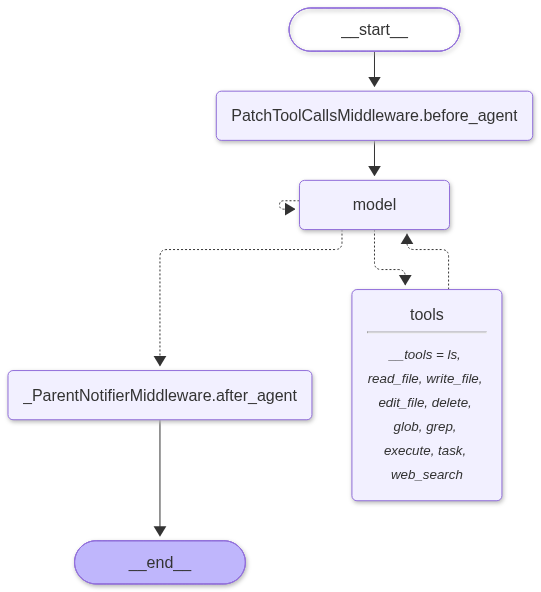

In [25]:
#Creating Basic Deep Agent
from deepagents import create_deep_agent
deepagent = create_deep_agent(
    model = models,
    tools=[web_search],
    system_prompt = """You are a helpful and intelligent AI assistant."""
)
deepagent

In [32]:
result = deepagent.invoke({
    "messages":[
        {"role":"user","content":"What is an Deep Agent."}
    ]
})
result
result["messages"][-1].content

'**Deep Agent** is a term used in the AI/ML community to describe a class of “agentic” systems that go beyond simple prompt‑based or single‑turn interactions.  They are designed to handle **complex, long‑running, multi‑step tasks** that require planning, memory, tool use, and sometimes even delegation to sub‑agents.  \n\nBelow is a concise overview of what Deep Agents are, why they matter, and what they can do.\n\n---\n\n## 1. Core Characteristics\n\n| Feature | Description | Why It Matters |\n|---------|-------------|----------------|\n| **Explicit Planning** | The agent builds a high‑level plan (e.g., “search, gather data, analyze, write report”) before executing actions. | Prevents the “guess‑and‑retry” cycle that shallow agents suffer from. |\n| **Persistent Memory** | Stores facts, intermediate results, and context across turns. | Enables continuity in long‑running conversations or workflows. |\n| **Tool Execution** | Calls APIs, runs code, interacts with external services. | Turn